# How much cropland do the public maps show, and does it matter for a flood trigger?

EDA of the public cropland maps in ZOA's areas (the five Aweil counties and Bor South) and in the whole of South Sudan. It feeds the report sections **context** and **business and data understanding**, and two parts of the **methodology** (labeller agreement, sample size).

What it shows:

1. **How much.** The 7 maps we stratify on (plus ASAP, the course data) give very different amounts of cropland.
2. **Where.** Where two maps call crop, it is rarely the same land. **What the papers found** for the same maps elsewhere in Africa (2b), including Esri's F1 of 0 in Mali.
3. **National pattern.** The maps do not follow the FAO/WFP crop assessment (CFSAM) from state to state.
4. **Time.** The same product changes a lot from one year to the next.
5. **Flood trigger.** The choice of map moves "flooded cropland", and so a trigger, by one to two orders of magnitude.
6. **Labellers, sample size and the interval.** How well two of us agree (preliminary), how many labelled points a yearly check needs, and whether the planned 95% interval holds (simulation, 9b).

**Labelling finished on 12 Oct 2026** (450 points, two labels each), so these figures can be shared with everyone; before that they were kept from the labellers, who had to label blind (METHODOLOGY.md section 4).

**How to run.** Open this notebook from `cropland/` (Jupyter then runs it there). It needs the course data (`data-JBG060-2026/` next to the repo, or the same folders in `raw_data/`) and the Earth Engine exports cached in `raw_data/cropland/eda/`. Without the cache, set `RUN_EARTH_ENGINE = True` and your own Earth Engine project below; the exports then run once as batch tasks (a few hours). Code: `eda_maps.py` (Earth Engine and the numbers), `eda_figures.py` (plots), `eda_labels.py` (labeller agreement), `efficiency.py` (sample size). Every figure has a CSV twin in `deliverables/cropland_report/tables/`.

In [1]:
import os
import numpy as np
import pandas as pd
from IPython.display import Image, display

os.environ.setdefault("CROPLAND_EE_PROJECT", "southsudan-509222")   # use your own Earth Engine project
import eda_maps as D
import eda_figures as F
import eda_labels as L
import efficiency as E
import evaluation as V

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
D.TABLES.mkdir(parents=True, exist_ok=True)
RUN_EARTH_ENGINE = False
AREA_NAME = {"aweil": "Aweil counties", "bor_south": "Bor South"}
TILE = {"aweil": "h20v08", "bor_south": "h21v08"}
print("course data:", D.COURSE)
print("cached exports:", sorted(p.name for p in D.CACHE.glob("*.npz")))

course data: C:\Users\20240996\OneDrive - TU Eindhoven\Courses\JBG060\data-JBG060-2026
cached exports: ['national.npz', 'stab_dw_aweil.npz', 'stab_dw_bor_south.npz', 'stab_esri_aweil.npz', 'stab_esri_bor_south.npz', 'zoa_aweil.npz', 'zoa_bor_south.npz']


## 0. Earth Engine exports (once)

Every map is turned into crop / not crop exactly as for the strata (`common.public_maps`, following Kerner et al. 2024), evaluated on a fine grid (~10 m in the study areas, ~15 m nationally, ~19 m for the yearly series) and counted inside every cell of the NASA flood grid (1/480 degree, ~232 m). Counting on the fine grid matters: reading a map at a coarse scale uses Earth Engine's pyramids, which drop a rare class such as crop. Because the counts sit on the flood grid, the flood overlay later is an exact join.

Check: the stratum areas this gives for Aweil (0 maps 94.97%, 1-2 maps 4.71%, 3+ maps 0.32%) are the ones in `strata_areas.csv`, which was computed independently at 10 m for the sample.

In [2]:
needed = [f"zoa_{a}" for a in D.C.AREAS] + ["national"] + [f"stab_{p}_{a}" for p in ("esri", "dw") for a in D.C.AREAS]
missing = [n for n in needed if not (D.CACHE / f"{n}.npz").exists()]
if missing and RUN_EARTH_ENGINE:
    ee = D.ee_init()
    parts = {n.split("_")[0] for n in missing}
    D.export(ee, parts)        # batch tasks: follow them with D.status(ee), then run D.download(ee, missing)
print("missing exports:", missing or "none")

missing exports: none


## 1. How much cropland? Seven maps, seven answers

Crop share of the land per map and county. Reference lines: the CFSAM cereal harvested area (a modelled figure: population x share of households farming x area per farming household, traditional sector only, cereals only) and, nationally, FAOSTAT arable land. Neither is ground truth; they show the order of magnitude official statistics work with.

In [3]:
cells = {a: D.zoa_cells(a) for a in D.C.AREAS}
shares = pd.concat([D.crop_shares(df).assign(area=a) for a, df in cells.items()])
shares.to_csv(D.TABLES / "crop_share_by_county.csv", index=False)
shares.pivot_table(index="map", columns="unit", values="crop_pct").round(2)

unit,Aweil Centre,Aweil East,Aweil North,Aweil South,Aweil West,Bor South,all counties
map,,,,,,,
asap_v04,0.04,3.00,0.67,1.76,0.51,0.01,0.97
deafrica_2019,0.22,4.37,1.85,2.31,1.62,0.00,1.77
dynamicworld_2022,0.15,2.63,0.20,1.13,0.52,21.34,0.79
dynamicworld_2025,0.04,0.69,0.08,0.15,0.21,8.99,0.22
esri_2022,0.16,1.28,0.19,0.10,0.34,0.06,0.42
esri_2025,0.26,1.04,0.14,0.07,0.30,0.03,0.39
gfsad_2015,0.13,4.48,1.52,5.34,1.80,0.22,1.92
glad_2019,0.33,1.66,0.88,0.80,1.85,0.25,1.00
worldcereal_2021,0.04,3.09,0.70,1.82,0.54,0.01,1.00


In [4]:
nat = D.national()
cache = D.CACHE / "national_by_county.pkl"
cty = pd.read_pickle(cache) if cache.exists() else D.national_by_county(nat)
cty.to_pickle(cache)
cty.to_csv(D.TABLES / "national_crop_by_county.csv", index=False)
maps = D.MAPS + D.EXTRA + ["asap_v04"]
land = cty.land_ha.sum()
national = pd.DataFrame({"crop_Mha": cty[maps].sum() / 1e6, "crop_pct_of_land": 100 * cty[maps].sum() / land})
national.to_csv(D.TABLES / "national_crop_share.csv")
print(f"land: {land / 1e6:.2f} Mha (incl. Abyei)")
national.round(3)

land: 64.27 Mha (incl. Abyei)


,crop_Mha,crop_pct_of_land
worldcover_2021,0.243,0.378
glad_2019,0.397,0.618
deafrica_2019,0.872,1.357
worldcereal_2021,0.439,0.683
esri_2025,0.223,0.347
dynamicworld_2025,1.797,2.796
gfsad_2015,0.738,1.147
esri_2022,0.179,0.278
dynamicworld_2022,2.523,3.925
asap_v04,0.407,0.634


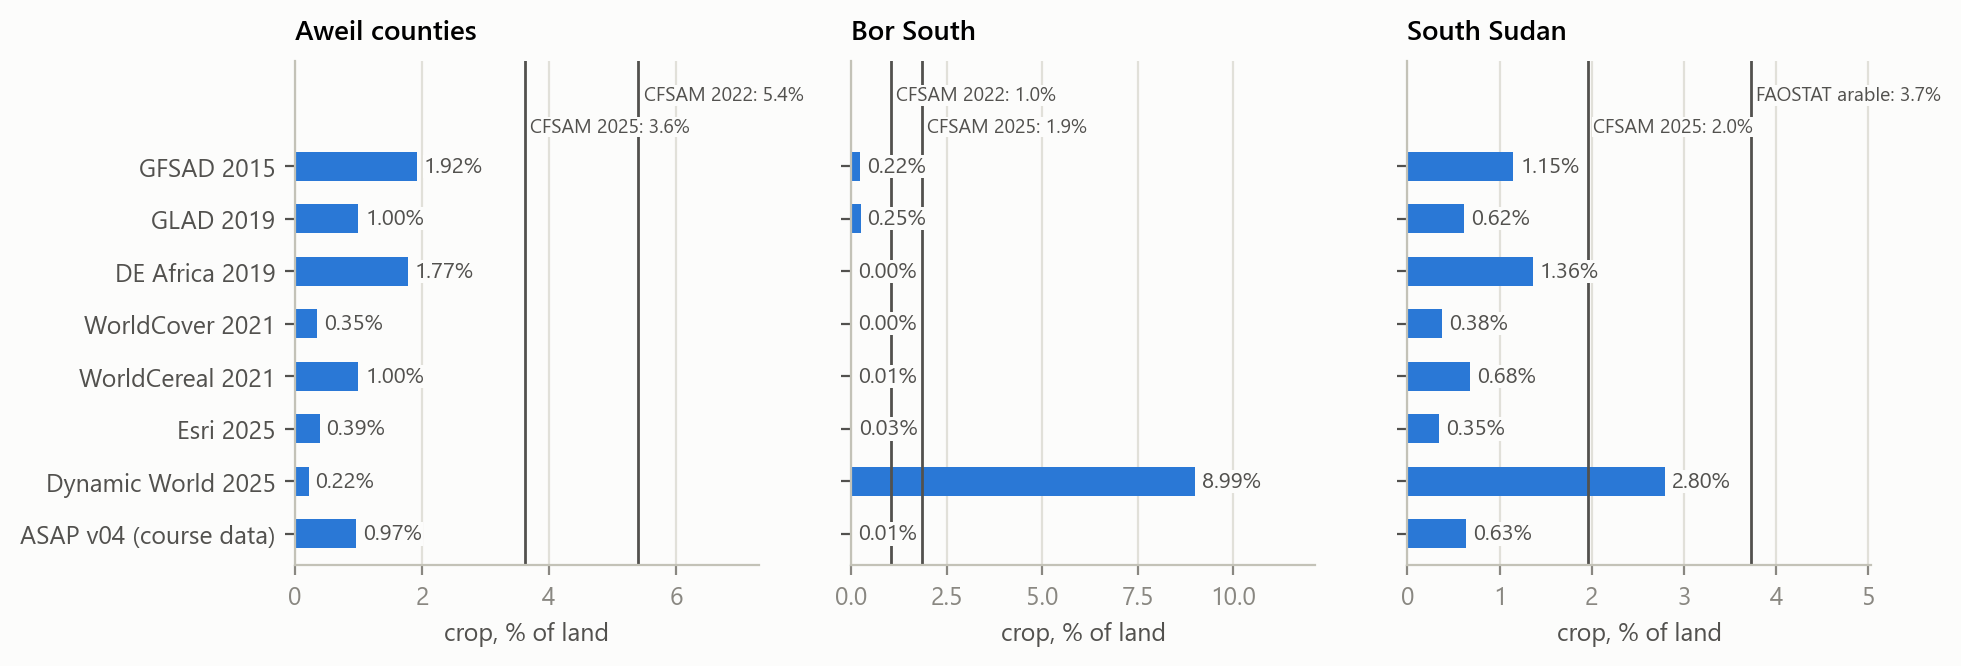

In [5]:
ref = pd.read_csv("reference_statistics.csv")
refn = pd.read_csv("reference_national.csv").set_index(["source", "year", "item"]).value
land_area = {a: float((df.inside * df.ha).sum()) for a, df in cells.items()}
county = ref[ref.level == "county"]
cfsam = {(a, y): county[(county.year == y) & county.name.str.startswith("Aweil" if a == "aweil" else "Bor")].cereal_harvested_ha.sum()
         for a in D.C.AREAS for y in (2022, 2025)}
refs = {AREA_NAME[a]: [(f"CFSAM {y}", 100 * cfsam[(a, y)] / land_area[a]) for y in (2025, 2022)] for a in D.C.AREAS}
refs["South Sudan"] = [("CFSAM 2025", 100 * refn[("CFSAM", 2025, "cereal harvested area")] / land),
                       ("FAOSTAT arable", 100 * refn[("FAOSTAT", 2022, "arable land")] / land)]
panels = {AREA_NAME[a]: shares[(shares.area == a) & shares.unit.isin(["all counties", "Bor South"])].set_index("map").crop_pct
          for a in D.C.AREAS}
panels["South Sudan"] = national.crop_pct_of_land
pd.DataFrame([{"panel": k, "line": l, "pct_of_land": float(v)} for k, vs in refs.items() for l, v in vs]).to_csv(D.TABLES / "reference_lines.csv", index=False)
display(Image(F.crop_share(panels, refs)))

## 2. Where? The maps hardly agree on which land is crop

Two views. The share of land called crop by at least *k* of the 7 maps (Kerner et al. 2024, Table 2, found unanimous crop on under 0.5% of every country they studied). And, for every two maps, the overlap of their crop class (intersection over union, IoU). Pixel agreement, the measure Kerner et al. report, looks high only because most land is "not crop" in every map; it is saved too.

,0 maps,1 maps,2 maps,3 maps,4 maps,5 maps,6 maps,7 maps
Aweil Centre,99.123,0.741,0.122,0.014,0.001,0.000,0.000,0.0
Aweil East,88.209,8.653,2.238,0.712,0.165,0.021,0.003,0.0
Aweil North,95.637,3.456,0.673,0.191,0.040,0.003,0.000,0.0
Aweil South,91.631,6.182,1.495,0.530,0.139,0.021,0.000,0.0
Aweil West,94.760,4.075,0.926,0.195,0.040,0.003,0.000,0.0
all counties,94.966,3.822,0.890,0.257,0.058,0.007,0.001,0.0
Bor South,90.560,9.373,0.063,0.004,0.000,0.000,0.000,0.0
South Sudan,94.517,4.517,0.542,0.144,0.116,0.155,0.009,0.0


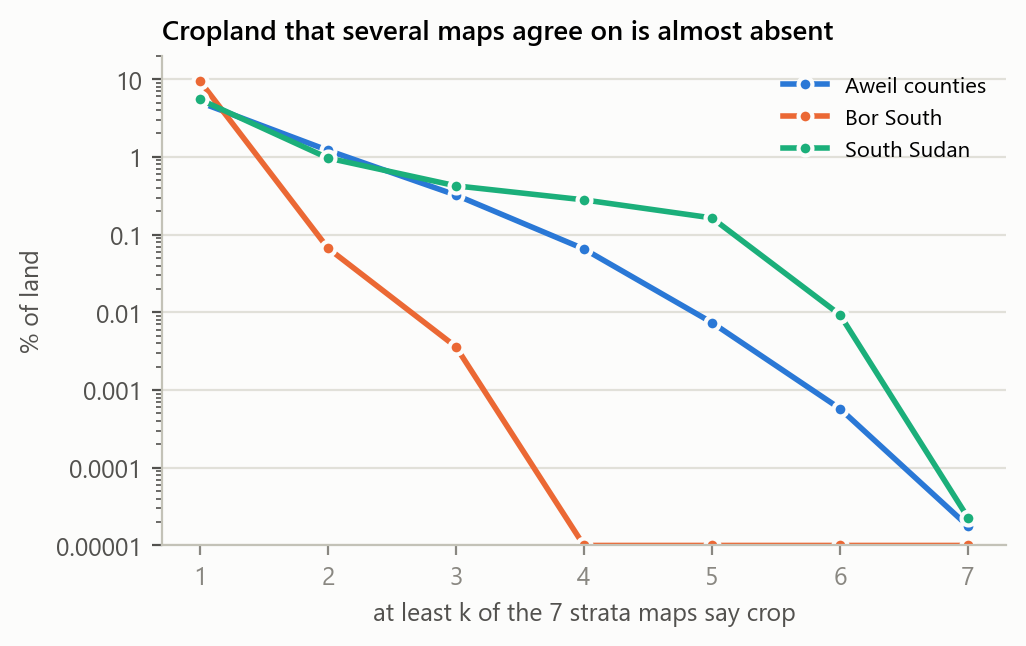

In [6]:
agree = {AREA_NAME[a]: D.agreement(df) for a, df in cells.items()}
agree["South Sudan"] = pd.DataFrame([100 * cty[[f"agree_{k}" for k in range(8)]].sum().to_numpy() / land],
                                    index=["South Sudan"], columns=[f"{k} maps" for k in range(8)])
agree_tab = pd.concat(agree.values())
agree_tab.to_csv(D.TABLES / "agreement_share_of_land.csv")
rows = {"Aweil counties": agree_tab.loc["all counties"], "Bor South": agree_tab.loc["Bor South"],
        "South Sudan": agree_tab.loc["South Sudan"]}
curves = {k: [v.iloc[j:].sum() for j in range(1, 8)] for k, v in rows.items()}
pd.DataFrame(curves, index=[f">= {j} maps" for j in range(1, 8)]).to_csv(D.TABLES / "agreement_at_least_k.csv")
display(agree_tab.round(3))
display(Image(F.agreement_curves(curves)))

Aweil counties: IoU 0.01-0.16, pixel agreement 0.967-0.995
Bor South: IoU 0.00-0.10, pixel agreement 0.908-1.000


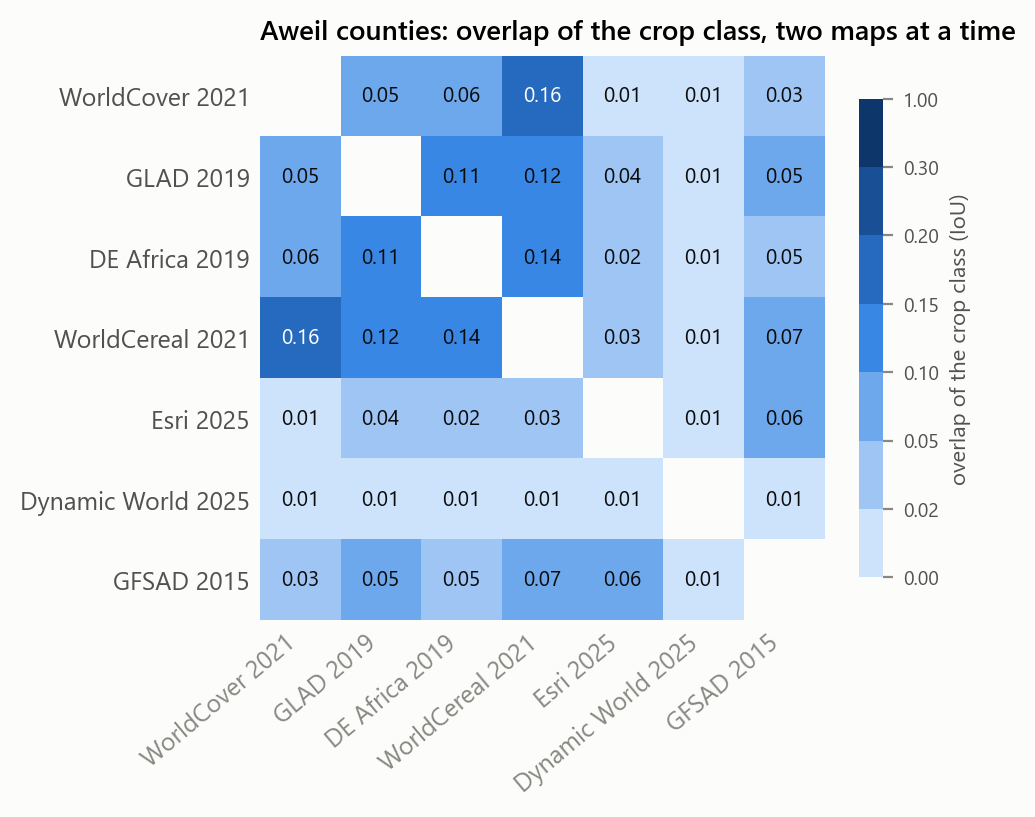

In [7]:
for a, df in cells.items():
    iou, kap, agr = D.pairwise(df)
    iou.to_csv(D.TABLES / f"pairwise_iou_{a}.csv")
    kap.to_csv(D.TABLES / f"pairwise_kappa_{a}.csv")
    agr.to_csv(D.TABLES / f"pairwise_pixel_agreement_{a}.csv")
    off = ~np.eye(len(iou), dtype=bool)
    print(f"{AREA_NAME[a]}: IoU {np.nanmin(iou.values[off]):.2f}-{np.nanmax(iou.values[off]):.2f}, "
          f"pixel agreement {np.nanmin(agr.values[off]):.3f}-{np.nanmax(agr.values[off]):.3f}")
iou_aweil = pd.read_csv(D.TABLES / "pairwise_iou_aweil.csv", index_col=0)
display(Image(F.pairwise_iou(iou_aweil, "Aweil counties: overlap of the crop class, two maps at a time", "03_pairwise_iou_aweil")))

## 2b. What the two papers found for these maps

Kerner et al. (2024, Table 1) and Adebayo et al. (2026, Table 3) scored six of our seven strata maps (all but WorldCereal) and ASAP against labelled points in 8 and 6 African countries. Neither covers South Sudan. The values are transcribed, with table and page, in `reference_accuracy_literature.csv`; as a check, F1 matches the harmonic mean of precision and recall in every country row.

Two lessons for us:

1. **Accuracy misleads when crop is rare.** In Mali (2% of the points are crop, the case most like Aweil) Esri reaches 0.97 accuracy with F1 = 0: it calls no point crop. So we report precision, recall and F1 with standard errors, as both papers do, never accuracy alone.
2. **Low recall elsewhere, little crop here.** The maps that miss most crop in the papers' countries (lowest recall) are the ones that show the least crop in Aweil. In Bor South the pattern breaks: Dynamic World, with the lowest published recall, shows the most crop there. Published scores do not predict that local failure; only local labels can.

Our own scores for the same maps, on our test points, come in the results (`09_score.py`, after all labels are in and Rule 1 is frozen).

,kerner_mean_f1,kerner_f1_lowest,kerner_f1_lowest_country,kerner_f1_highest,kerner_f1_mali,kerner_accuracy_mali,kerner_mean_precision,kerner_mean_recall,adebayo_mean_f1,adebayo_mean_recall,aweil_crop_pct,bor_south_crop_pct
map,,,,,,,,,,,,
asap_v04,0.52,0.21,Mali,0.74,0.21,0.95,0.47,0.69,NaN,NaN,0.97,0.01
deafrica_2019,0.63,0.43,Uganda,0.85,0.46,0.96,0.56,0.81,0.62,0.73,1.77,0.00
dynamicworld_2025,0.34,0.12,Mali,0.63,0.12,0.94,0.63,0.30,0.34,0.27,0.22,8.99
esri_2025,0.43,0.00,Mali,0.75,0.00,0.97,0.63,0.38,0.49,0.40,0.39,0.03
gfsad_2015,0.58,0.15,Mali,0.76,0.15,0.91,0.51,0.74,NaN,NaN,1.92,0.22
glad_2019,0.65,0.33,Mali,0.75,0.33,0.96,0.68,0.68,0.64,0.66,1.00,0.25
worldcover_2021,0.65,0.43,Kenya,0.82,0.43,0.95,0.72,0.65,NaN,NaN,0.35,0.00


,Kerner recall (7 maps),Adebayo recall (4 maps)
Aweil counties,0.89,1.0
Bor South,-0.39,-0.8


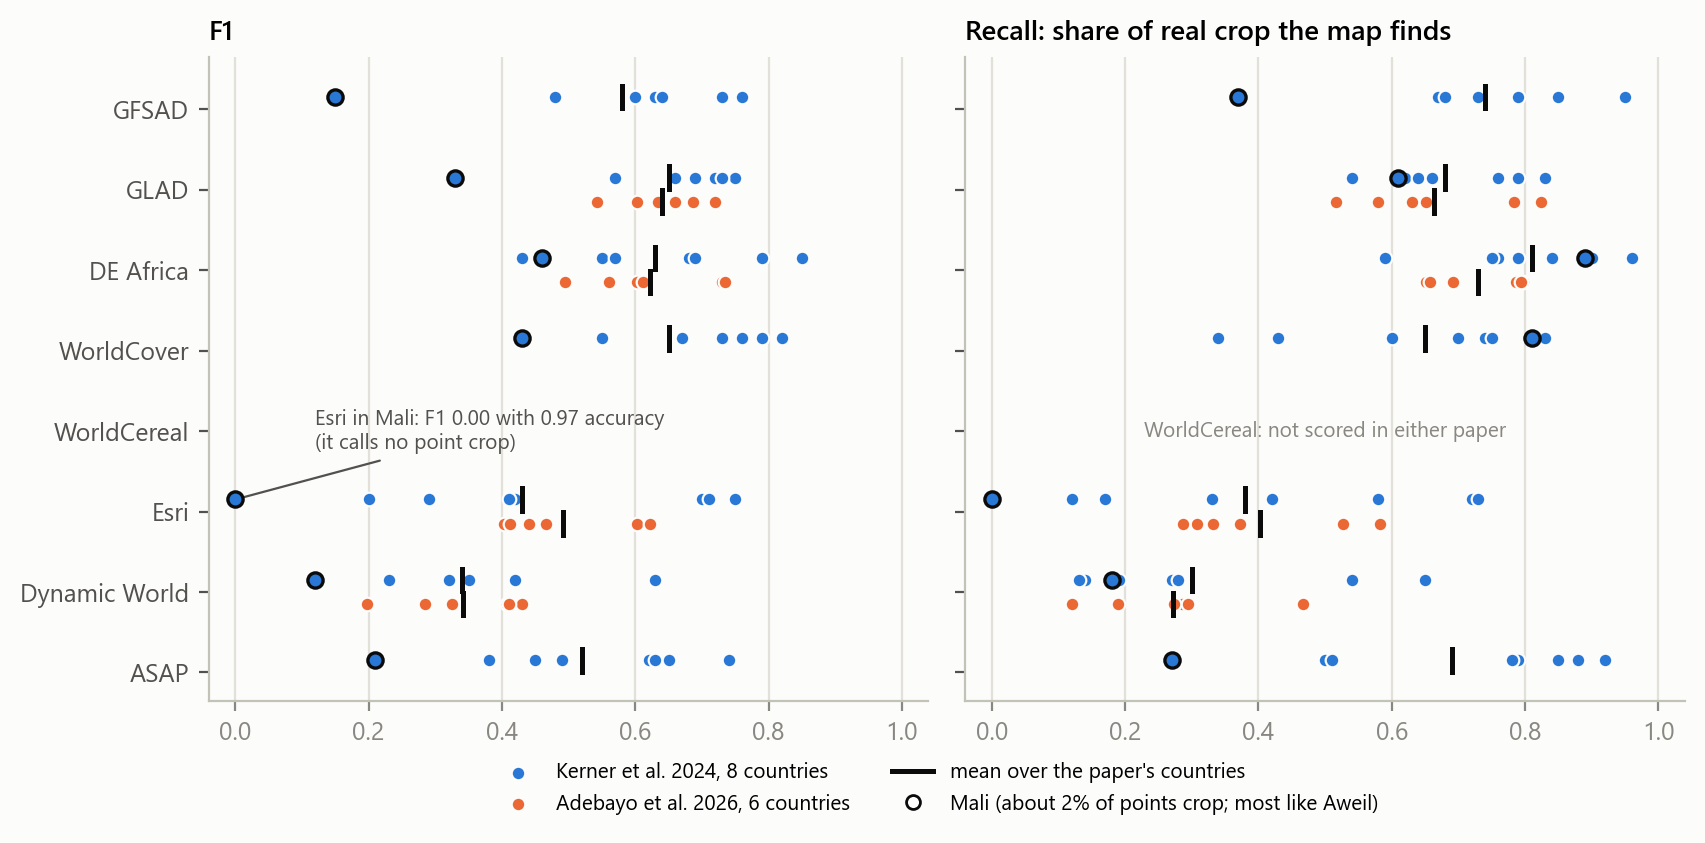

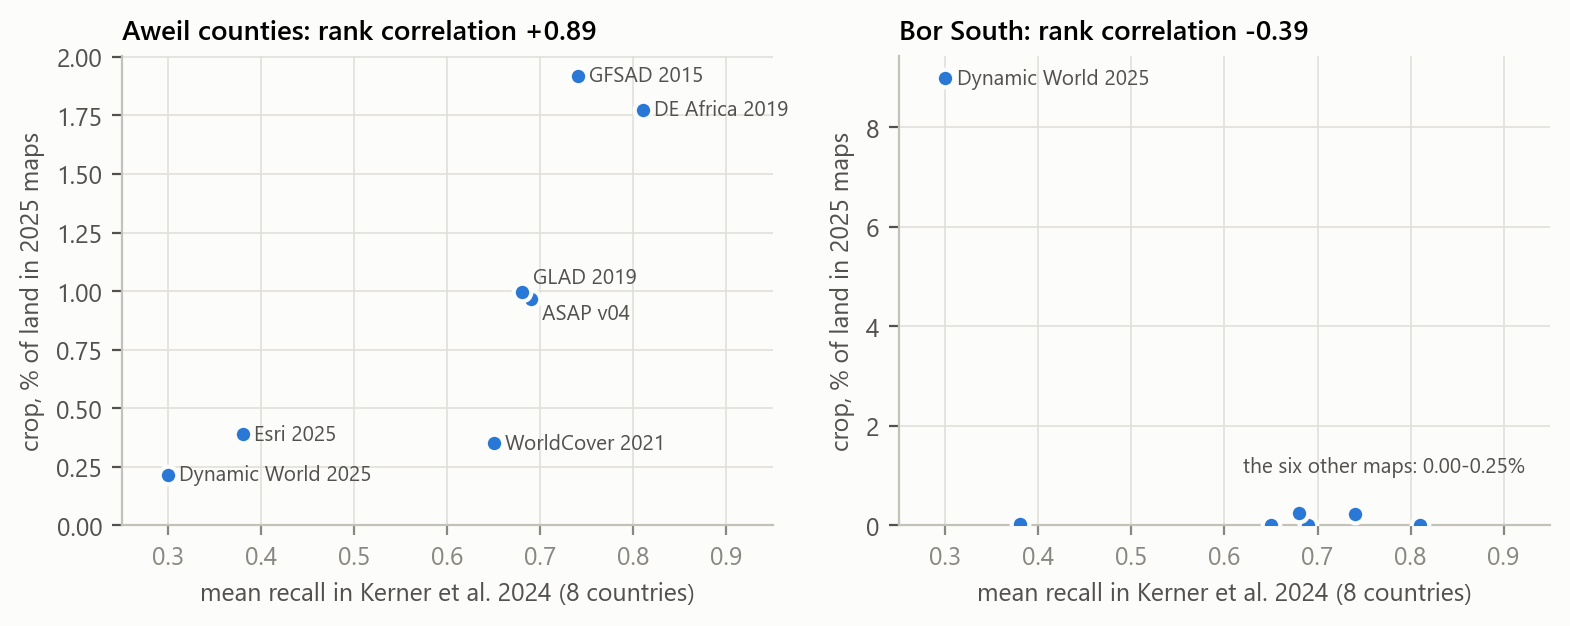

In [8]:
from scipy.stats import spearmanr
lit = pd.read_csv("reference_accuracy_literature.csv")
ours = {"esri": "esri_2025", "dynamicworld": "dynamicworld_2025", "deafrica": "deafrica_2019", "worldcover": "worldcover_2021",
        "gfsad": "gfsad_2015", "glad": "glad_2019", "asap": "asap_v04"}
k = lit[(lit.source == "Kerner et al. 2024") & lit["map"].isin(ours)]
a = lit[(lit.source == "Adebayo et al. 2026") & lit["map"].isin(ours)]
per = lambda t, metric: t[(t.metric == metric) & (t.country != "Mean")].pivot(index="map", columns="country", values="value")
f1k = per(k, "f1")
pub = pd.DataFrame({
    "kerner_mean_f1": k[(k.metric == "f1") & (k.country == "Mean")].set_index("map").value,
    "kerner_f1_lowest": f1k.min(axis=1), "kerner_f1_lowest_country": f1k.idxmin(axis=1),
    "kerner_f1_highest": f1k.max(axis=1), "kerner_f1_mali": f1k["Mali"],
    "kerner_accuracy_mali": per(k, "accuracy")["Mali"],
    "kerner_mean_precision": k[(k.metric == "precision") & (k.country == "Mean")].set_index("map").value,
    "kerner_mean_recall": k[(k.metric == "recall") & (k.country == "Mean")].set_index("map").value,
    "adebayo_mean_f1": a[(a.metric == "f1") & (a.country == "Mean")].set_index("map").value,
    "adebayo_mean_recall": a[(a.metric == "recall") & (a.country == "Mean")].set_index("map").value,
}).rename(index=ours)
aw = panels["Aweil counties"]
bs = panels["Bor South"]
pub["aweil_crop_pct"] = aw.reindex(pub.index)
pub["bor_south_crop_pct"] = bs.reindex(pub.index)
pub.to_csv(D.TABLES / "published_accuracy_of_our_maps.csv")
rho = pd.DataFrame({src: {area: spearmanr(pub[col].dropna(), pub.loc[pub[col].notna(), crop]).correlation
                          for area, crop in (("Aweil counties", "aweil_crop_pct"), ("Bor South", "bor_south_crop_pct"))}
                    for src, col in (("Kerner recall (7 maps)", "kerner_mean_recall"), ("Adebayo recall (4 maps)", "adebayo_mean_recall"))})
rho.to_csv(D.TABLES / "published_recall_vs_crop_share_rank_correlation.csv")
display(pub.round(2))
display(rho.round(2))
display(Image(F.published_accuracy(lit)))
display(Image(F.recall_vs_share(pd.DataFrame({"recall": pub.kerner_mean_recall, "aweil": pub.aweil_crop_pct,
                                              "bor_south": pub.bor_south_crop_pct}))))

## 3. The national pattern does not follow the crop assessment

Crop area per state and map against CFSAM's cereal harvested area. CFSAM's Pibor and Ruweng administrative areas are added to Jonglei and Unity (our 10-state boundaries). CFSAM covers the traditional smallholder sector only, so mechanised schemes (Upper Nile, around Renk) are missing from it. A high rank correlation would mean a map puts more crop where CFSAM does.

,worldcover_2021,glad_2019,deafrica_2019,worldcereal_2021,esri_2025,dynamicworld_2025,gfsad_2015,esri_2022,dynamicworld_2022,asap_v04,cfsam_2025_kha,cfsam_2022_kha
state,,,,,,,,,,,,
Abyei Region,2.0,1.6,15.1,1.9,0.4,2.7,7.5,0.6,4.8,1.9,7.005,7.964
Central Equatoria,2.0,61.3,2.1,11.2,10.3,11.5,117.0,7.3,90.8,10.2,120.600,82.619
Eastern Equatoria,14.0,30.5,96.8,159.5,59.7,357.6,21.2,32.2,800.8,114.1,155.634,133.950
Jonglei,0.1,3.8,3.3,0.4,8.4,624.9,137.3,10.6,784.3,0.4,91.539,63.378
Lakes,1.2,32.9,0.5,5.4,25.1,13.7,83.9,27.6,33.7,5.1,186.953,161.687
Northern Bahr el Ghazal,10.8,30.7,54.7,30.8,12.0,6.7,59.2,13.1,24.5,29.8,111.530,166.843
Unity,2.3,7.6,20.3,7.6,25.2,136.5,8.8,24.5,136.3,7.4,27.461,16.912
Upper Nile,184.1,170.7,550.3,180.5,62.6,626.5,27.7,41.8,605.2,180.8,88.816,48.454
Warrap,19.8,39.3,118.3,34.2,11.4,9.9,205.1,11.6,20.6,33.4,181.463,179.533


,2022,2025
worldcover_2021,0.16,-0.15
glad_2019,0.38,0.22
deafrica_2019,-0.05,-0.36
worldcereal_2021,0.18,-0.08
esri_2025,0.10,0.01
dynamicworld_2025,-0.23,-0.17
gfsad_2015,0.65,0.59
esri_2022,0.07,-0.05
dynamicworld_2022,-0.13,-0.05
asap_v04,0.37,0.25


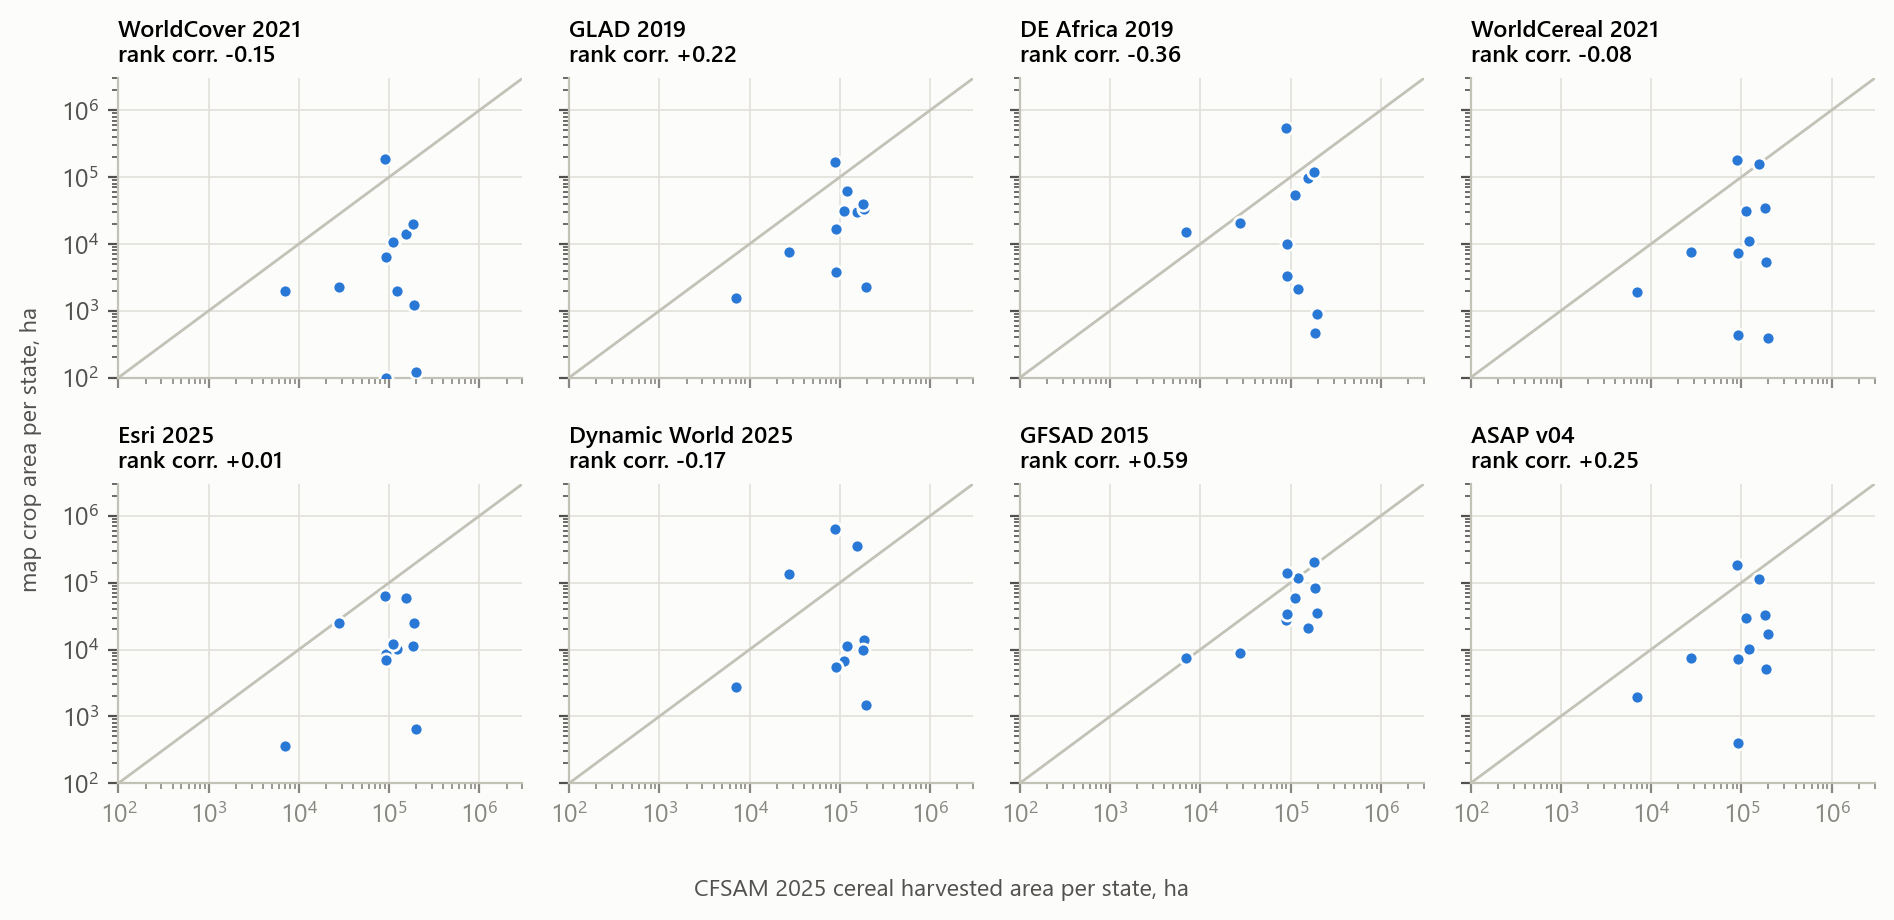

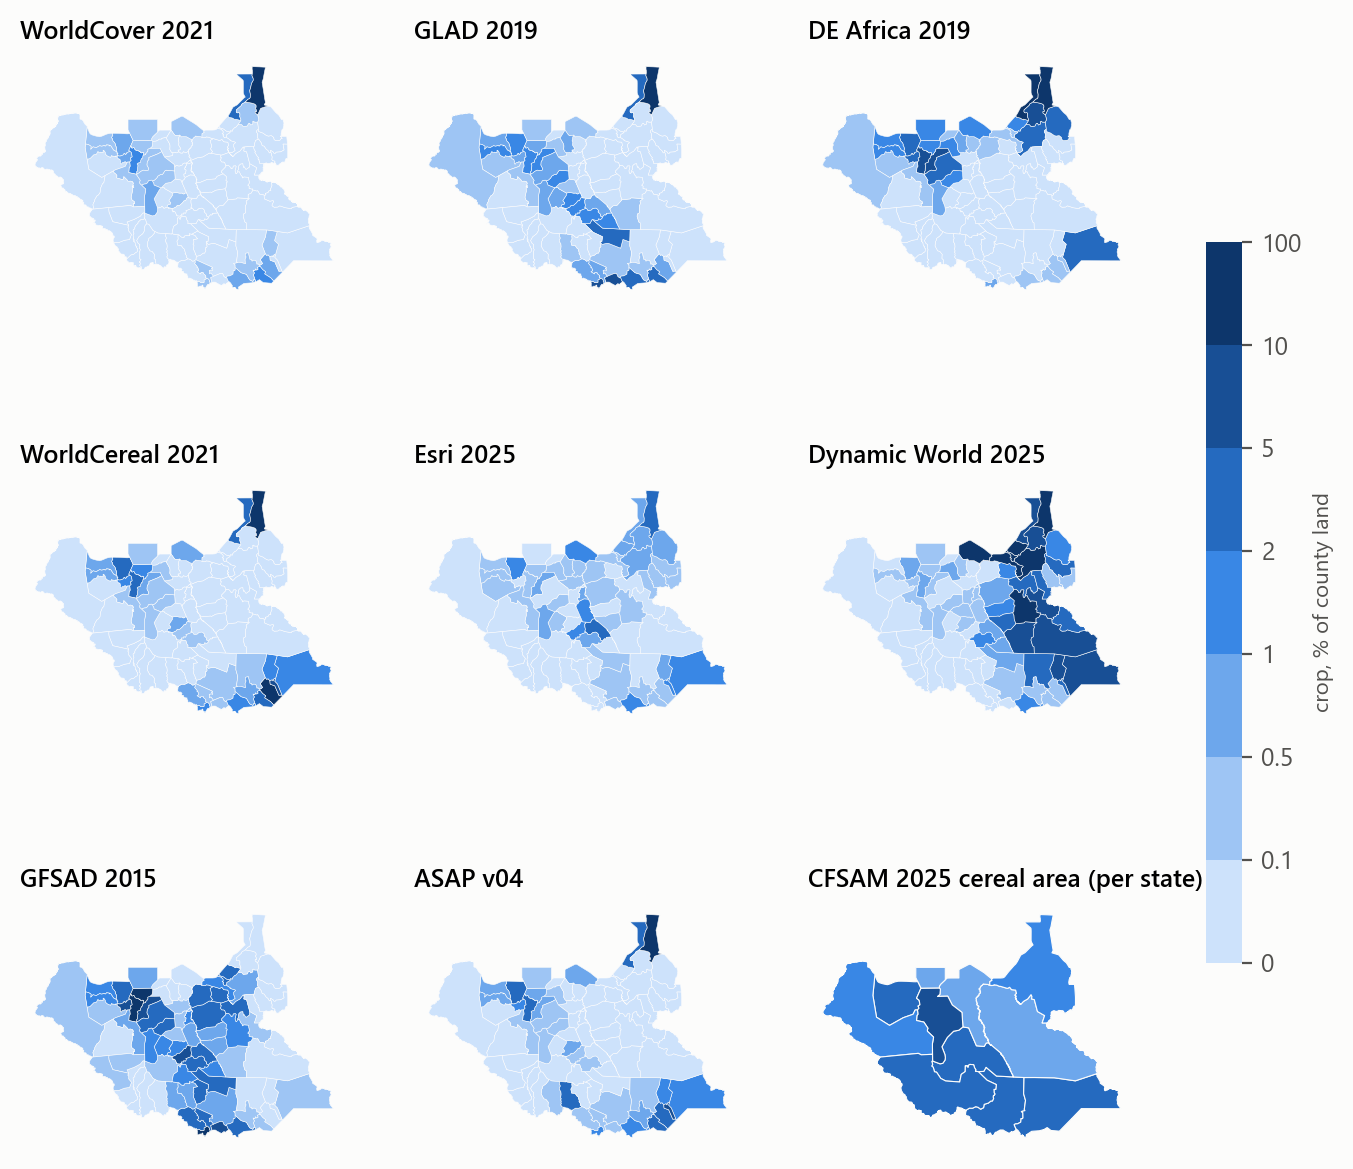

In [9]:
from scipy.stats import spearmanr
st = cty.groupby("state").sum(numeric_only=True)
cf = {y: ref[(ref.year == y) & (ref.level == "state")].groupby("state10").cereal_harvested_ha.sum() for y in (2022, 2025)}
comp = (st[maps] / 1e3).round(1).join((cf[2025] / 1e3).rename("cfsam_2025_kha")).join((cf[2022] / 1e3).rename("cfsam_2022_kha"))
comp.to_csv(D.TABLES / "state_crop_area_vs_cfsam_kha.csv")
rank = pd.DataFrame({y: {m: spearmanr(st[m], cf[y].reindex(st.index)).correlation for m in maps} for y in (2022, 2025)})
rank.to_csv(D.TABLES / "state_rank_correlation_with_cfsam.csv")
display(comp)
display(rank.round(2))
display(Image(F.states_vs_cfsam(st, cf[2025], D.MAPS + ["asap_v04"], 2025)))
display(Image(F.national_choropleths(cty, D.admin(2), D.MAPS + ["asap_v04"], cfsam_state=100 * cf[2025] / st.land_ha)))

## 4. Same product, different year

Esri (2017-2025) and Dynamic World (2016-2025) are remade every year from new images. Fields do move and lie fallow, but not by a factor of several from one year to the next. `still_crop_next_year_pct` is the share of one year's crop that the same product calls crop again the next year.

area    aweil       bor_south      
product    dw  esri        dw  esri
year                               
2016     1.33   NaN     13.10   NaN
2017     0.51  0.71     10.96  0.02
2018     0.80  0.61     10.54  0.01
2019     2.09  0.77      7.07  0.10
2020     0.42  0.36      0.57  0.01
2021     0.67  0.44      2.11  0.03
2022     0.79  0.42     21.33  0.06
2023     0.56  0.32      1.98  0.01
2024     0.36  0.45      5.52  0.00
2025     0.21  0.39      8.99  0.03
all      0.01  0.06      0.01  0.00
any      3.83  1.61     38.26  0.25

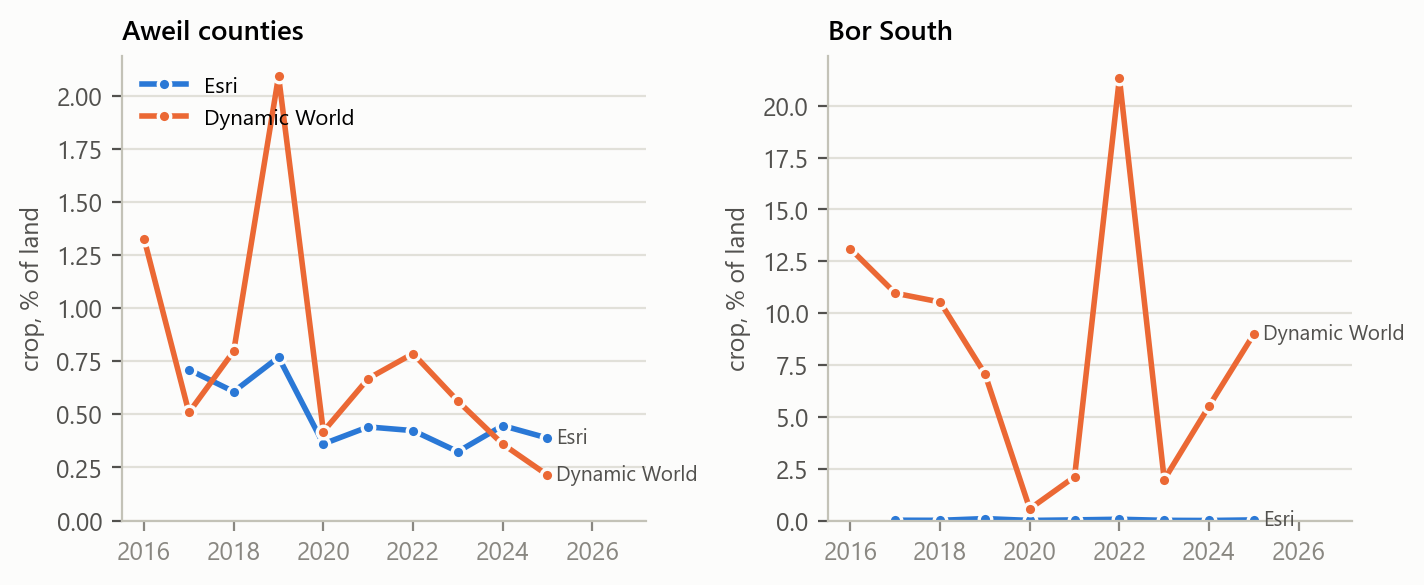

In [10]:
stab = pd.concat([D.stability(a) for a in D.C.AREAS], ignore_index=True)
if len(stab):
    stab.to_csv(D.TABLES / "same_map_every_year.csv", index=False)
    display(stab.pivot_table(index="year", columns=["area", "product"], values="crop_pct", aggfunc="first").round(2))
    display(Image(F.stability(stab)))
else:
    print("yearly exports not cached yet (stab_*.npz)")

## 5. Flooded cropland under each map, and a trigger

NASA MCDWD flood masks (course data, recurring + unusual), cells flooded on at least 1 (and at least 10) days between June and December, laid over each map: the Pacetti et al. (2017) overlay that a "flood inundating cropland" trigger rests on. For 2022 the yearly products are their 2022 versions. The flood masks stop at 10 N, so the national row covers the country south of 10 N. CFSAM 2022 reports 130,000 ha of cultivated land damaged by floods nationally.

unit              Aweil counties         Bor South         South Sudan (south of 10 N)         
year                        2022    2025      2022    2025                        2022     2025
map                                                                                            
asap_v04                  1104.0   110.0       0.0     0.0                      3884.0    755.0
deafrica_2019              887.0   306.0       2.0     1.0                     13993.0   2380.0
dynamicworld_2022         5805.0  1232.0     541.0  4971.0                     21342.0  23628.0
dynamicworld_2025          850.0   237.0     105.0  1600.0                     12317.0  16010.0
esri_2022                  493.0    97.0      21.0     2.0                      1825.0   1328.0
esri_2025                  331.0    10.0       1.0     0.0                      1820.0    503.0
gfsad_2015                3572.0   141.0      29.0    10.0                     21353.0   1403.0
glad_2019                  481.0    98.0      20.0     0.0                      2584.0    543.0
worldcereal_2021          1002.0    77.0       0.0     0.0                      3842.0    739.0
worldcover_2021            432.0    42.0       0.0     0.0                      1193.0    170.0

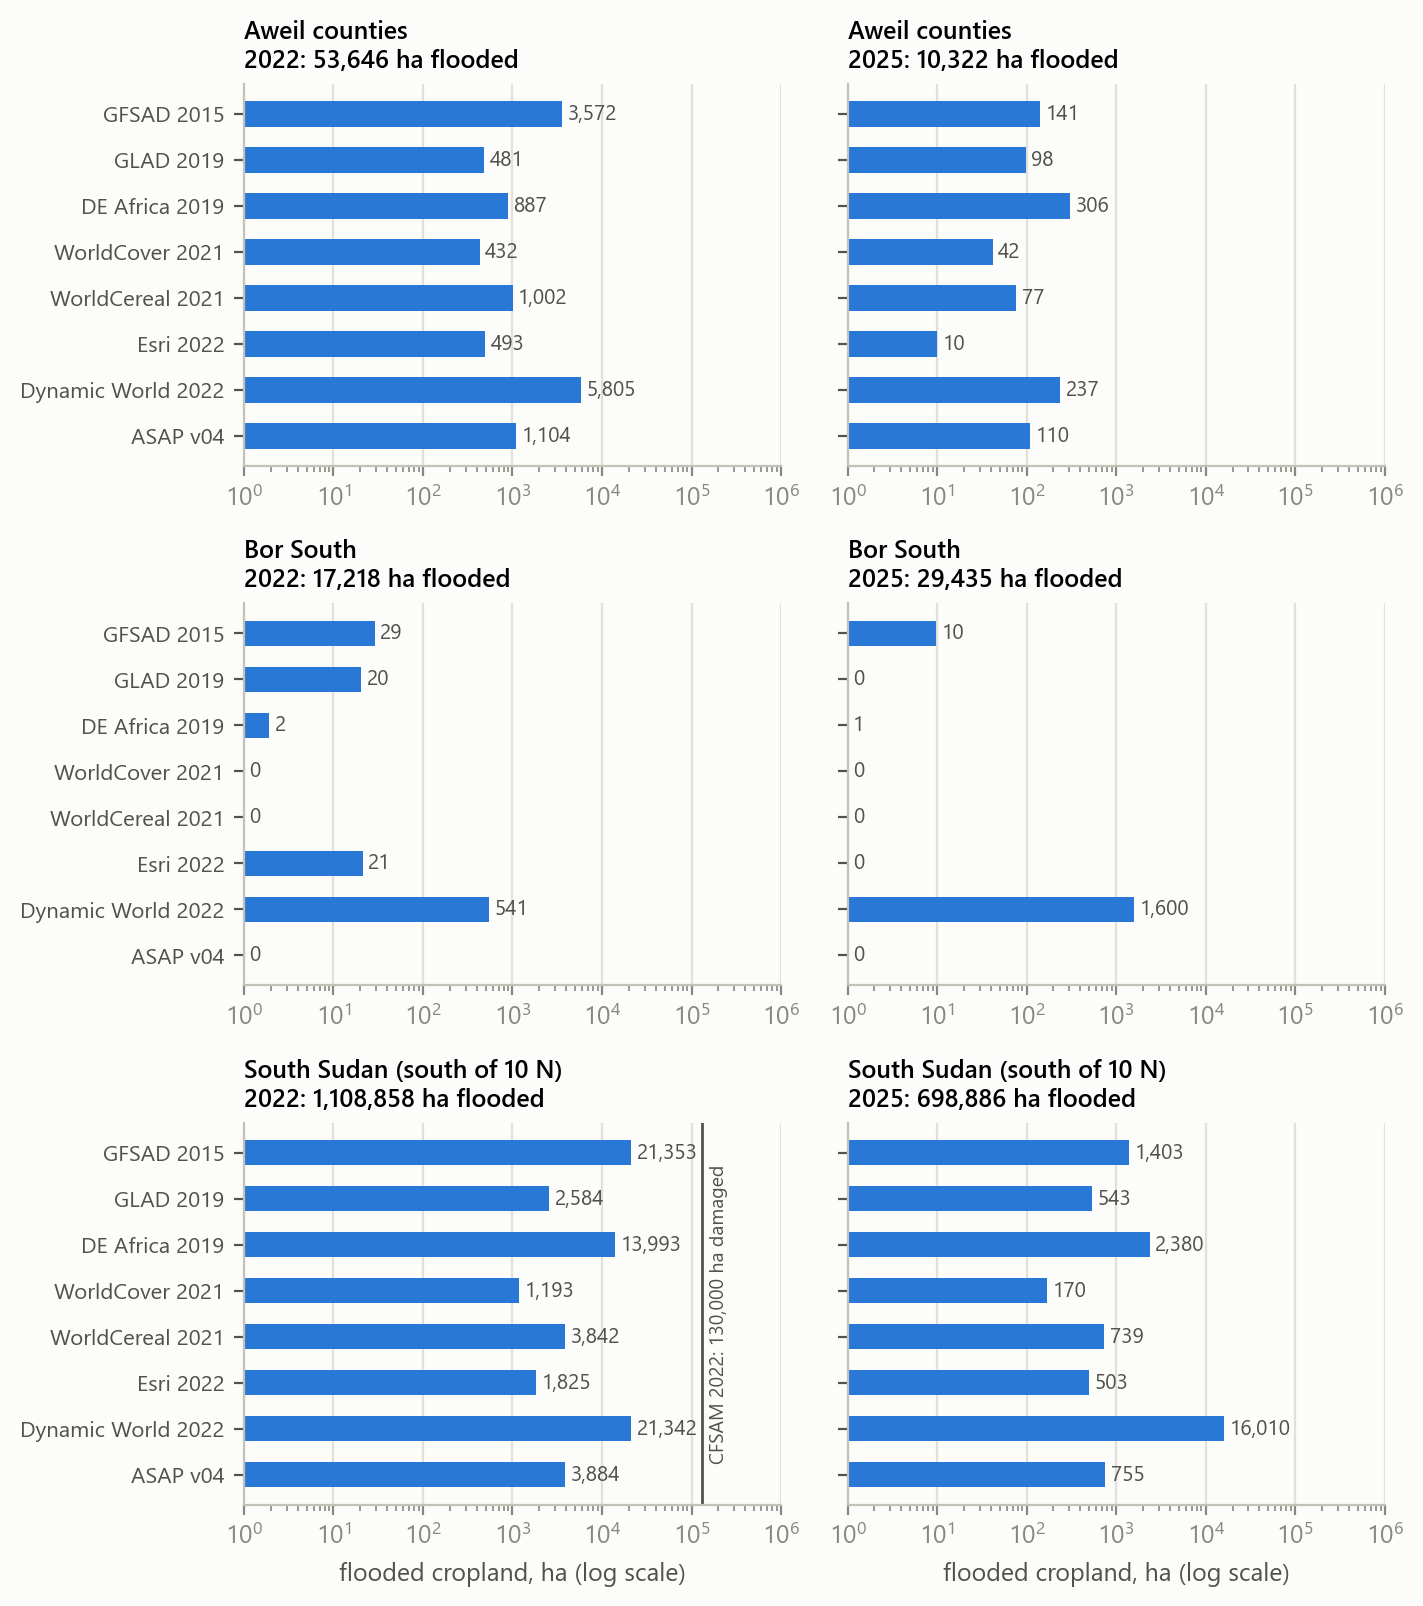

In [11]:
rows = []
for a, df in cells.items():
    for yr in (2022, 2025):
        fl = D.flood_cells(TILE[a], yr)
        for md_ in (1, 10):
            rows.append(D.flooded_crop(df, fl, min_days=md_).assign(unit=AREA_NAME[a], year=yr, min_days=md_))
for yr in (2022, 2025):
    for md_ in (1, 10):
        rows.append(D.national_flooded_crop(nat, yr, md_).assign(unit="South Sudan (south of 10 N)", min_days=md_))
flood_tab = pd.concat(rows, ignore_index=True)
flood_tab.to_csv(D.TABLES / "flooded_cropland_per_map.csv", index=False)
show = flood_tab[flood_tab.min_days == 1]
display(show.pivot_table(index="map", columns=["unit", "year"], values="flooded_crop_ha").round(0))
cf_refs = {("South Sudan (south of 10 N)", 2022): [("CFSAM 2022: 130,000 ha damaged", 130000)]}
display(Image(F.flooded(show, cf_refs)))

In [12]:
# a hard trigger on hectares (Q&A 2, slide 31): which maps would fire it?
def same_year(m, yr):
    return m.replace("_2025", f"_{yr}") if m.startswith(("esri", "dynamicworld")) else m

trig = []
for (u, yr), t in show.groupby(["unit", "year"]):
    v = t.set_index("map").flooded_crop_ha
    v = v[[same_year(m, yr) for m in D.MAPS] + ["asap_v04"]]
    for thr in (100, 500, 1000, 5000):
        fire = v[v >= thr]
        trig.append({"unit": u, "year": yr, "threshold_ha": thr, "maps_firing": len(fire), "of": len(v),
                     "which": ", ".join(D.NAMES[m] for m in fire.index),
                     "min_ha": v.min(), "max_ha": v.max()})
trig = pd.DataFrame(trig)
trig.to_csv(D.TABLES / "trigger_check.csv", index=False)
trig

,unit,year,threshold_ha,maps_firing,of,which,min_ha,max_ha
0,Aweil counties,2022,100,8,8,"WorldCover 2021, GLAD 2019, DE Africa 2019, Wo...",431.960157,5804.785384
1,Aweil counties,2022,500,5,8,"DE Africa 2019, WorldCereal 2021, Dynamic Worl...",431.960157,5804.785384
2,Aweil counties,2022,1000,4,8,"WorldCereal 2021, Dynamic World 2022, GFSAD 20...",431.960157,5804.785384
3,Aweil counties,2022,5000,1,8,Dynamic World 2022,431.960157,5804.785384
4,Aweil counties,2025,100,4,8,"DE Africa 2019, Dynamic World 2025, GFSAD 2015...",10.023263,306.228129
5,Aweil counties,2025,500,0,8,,10.023263,306.228129
6,Aweil counties,2025,1000,0,8,,10.023263,306.228129
7,Aweil counties,2025,5000,0,8,,10.023263,306.228129
8,Bor South,2022,100,1,8,Dynamic World 2022,0.000000,541.335033
9,Bor South,2022,500,1,8,Dynamic World 2022,0.000000,541.335033


## 6. Along the Lol

ZOA works along the Lol river (Q&A 2, slide 3). As a proxy for ZOA's communities we take land within 5 km of the Lol (OpenStreetMap line, `lol_river_osm.geojson`) inside the Aweil counties.

strip: 246,894 ha, 8.0% of the Aweil counties


,strip,rest,ratio_strip_to_rest
worldcover_2021,2.13,0.20,10.87
glad_2019,2.64,0.85,3.09
deafrica_2019,4.47,1.54,2.90
worldcereal_2021,3.27,0.80,4.08
esri_2025,0.25,0.40,0.63
dynamicworld_2025,1.07,0.14,7.53
gfsad_2015,2.44,1.87,1.30
esri_2022,0.37,0.43,0.86
dynamicworld_2022,5.09,0.42,12.09
asap_v04,3.18,0.77,4.12


year,2022,2025
map,,
asap_v04,438.0,102.0
deafrica_2019,519.0,304.0
dynamicworld_2022,3575.0,1058.0
dynamicworld_2025,586.0,224.0
esri_2022,48.0,38.0
esri_2025,31.0,7.0
gfsad_2015,736.0,91.0
glad_2019,335.0,98.0
worldcereal_2021,364.0,75.0


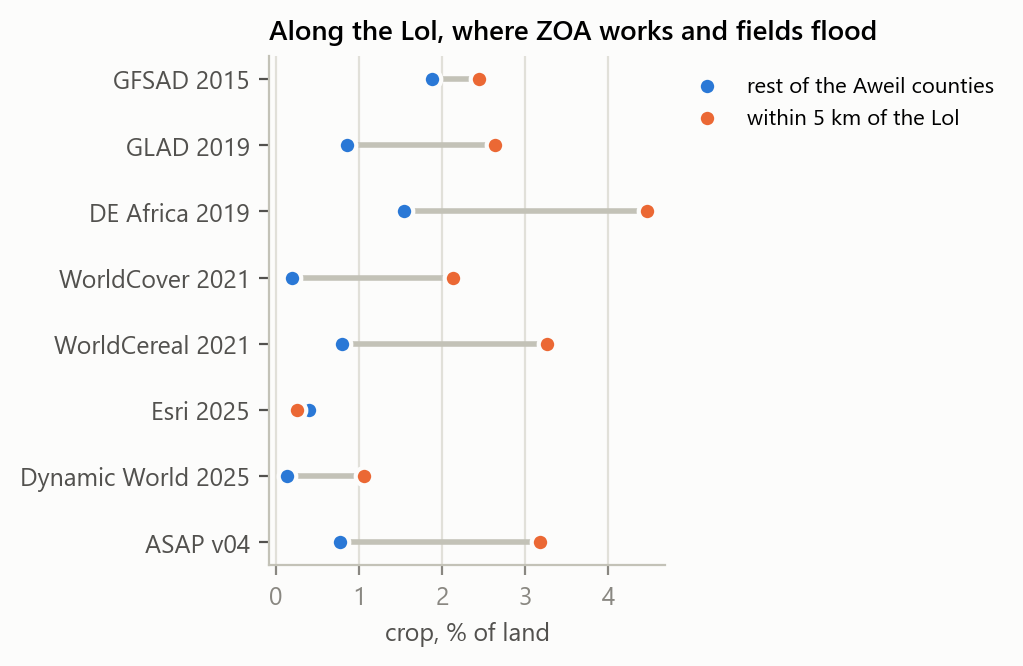

In [13]:
aw = cells["aweil"].copy()
aw["lol_km"] = D.lol_distance_km(aw)
w = aw.inside * aw.ha
strip = aw.lol_km <= 5
lol = pd.DataFrame({"strip": [100 * (aw[m] * w)[strip].sum() / w[strip].sum() for m in maps],
                    "rest": [100 * (aw[m] * w)[~strip].sum() / w[~strip].sum() for m in maps]}, index=maps)
lol["ratio_strip_to_rest"] = lol.strip / lol.rest
print(f"strip: {w[strip].sum():,.0f} ha, {100 * w[strip].sum() / w.sum():.1f}% of the Aweil counties")
fl_strip = []
for yr in (2022, 2025):
    f = D.flooded_crop(aw[strip], D.flood_cells("h20v08", yr), min_days=1)
    fl_strip.append(f.assign(year=yr))
fl_strip = pd.concat(fl_strip)
lol.to_csv(D.TABLES / "lol_strip_crop_share.csv")
fl_strip.to_csv(D.TABLES / "lol_strip_flooded_cropland.csv", index=False)
display(lol.round(2))
display(fl_strip.pivot_table(index="map", columns="year", values="flooded_crop_ha").round(0))
display(Image(F.lol_strip(lol)))

## 7. What the choice of map does to a damage or cash estimate (illustration)

Upper bound only: it assumes every flooded crop field is lost, which CFSAM says did not happen in 2025 (floods came late, crops were mature). The point is the spread between maps, not the level. Inputs: CFSAM net cereal yield and area per farming household of the same year (`reference_statistics.csv`), 110 kg cereal per person per year (CFSAM), and, as an assumption to check before quoting, the REACH JMMI 2025 figures: survival basket about USD 149 per 6-person household per month (August 2025), sorghum about USD 0.63 per kg (October 2025).

In [14]:
def per_area(a, yr):
    t = county[(county.year == yr) & county.name.str.startswith("Aweil" if a == "aweil" else "Bor")]
    return t.net_cereal_t.sum() / t.cereal_harvested_ha.sum(), t.cereal_harvested_ha.sum() / t.farming_households.sum()

nat_rows = ref[ref.level == "national"].set_index("year")
size = []
for (u, yr), t in show.groupby(["unit", "year"]):
    a = {"Aweil counties": "aweil", "Bor South": "bor_south"}.get(u)
    if a:
        y_net, ha_hh = per_area(a, yr)
    else:
        y_net = nat_rows.loc[yr, "net_cereal_t"] / nat_rows.loc[yr, "cereal_harvested_ha"] if yr in nat_rows.index else np.nan
        ha_hh = nat_rows.loc[yr, "ha_per_farming_household"] if yr in nat_rows.index else np.nan   # national average (2022 only)
    for m, ha in t.set_index("map").flooded_crop_ha.items():
        if m not in [same_year(x, yr) for x in D.MAPS] + ["asap_v04"]:
            continue                                       # Esri / Dynamic World: only the version of that year
        size.append({"unit": u, "year": yr, "map": m, "flooded_crop_ha": ha, "net_yield_t_ha": y_net,
                     "cereal_t": ha * y_net, "people_fed_one_year": ha * y_net / 0.110,
                     "farming_households": ha / ha_hh if ha_hh == ha_hh else np.nan,
                     "harvest_value_usd": ha * y_net * 630, "basket_usd_one_month": ha / ha_hh * 149 if ha_hh == ha_hh else np.nan})
size = pd.DataFrame(size)
size.to_csv(D.TABLES / "damage_and_cash_sizing.csv", index=False)
size.groupby(["unit", "year"]).agg(min_t=("cereal_t", "min"), max_t=("cereal_t", "max"),
                                   min_hh=("farming_households", "min"), max_hh=("farming_households", "max")).round(0)

min_t    max_t  min_hh   max_hh
unit                        year                                  
Aweil counties              2022   302.0   4060.0   568.0   7636.0
                            2025     8.0    235.0    13.0    399.0
Bor South                   2022     0.0    325.0     0.0    742.0
                            2025     0.0    896.0     0.0   2051.0
South Sudan (south of 10 N) 2022  1035.0  18529.0  1325.0  23726.0
                            2025   164.0  15427.0     NaN      NaN

## 8. Methodology: how well do two labellers agree?

Labels only, no features or maps, so nothing leaks into Rule 1. Each sample point is labelled by two of five people, blind to each other and to every map. Kappa corrects agreement for chance (Cohen 1960), but drops to 0 when one class is rare even if people almost always agree, so we also give positive and negative specific agreement (Cicchetti and Feinstein 1990). All 450 points, labelled twice (finished 12 Oct 2026). Where the two split on cropland versus not, we also list which of their answers differed (cover class, crop cues), to see what the disagreement is about.

450 of 450 points labelled twice


,by,group,points,cropland_agree,cropland_kappa,cropland_pos_agree,cropland_neg_agree,cropland_either_says
0,all,all,450,0.856,0.704,0.839,0.903,200
1,area,aweil,330,0.833,0.679,0.862,0.862,190
2,area,bor_south,120,0.917,0.144,0.182,0.960,10
3,area x stratum,"('aweil', 'A')",150,0.913,0.576,0.645,0.958,22
4,area x stratum,"('aweil', 'B')",90,0.711,0.317,0.841,0.524,78
5,area x stratum,"('aweil', 'C')",90,0.822,-0.074,0.919,0.000,90
6,area x stratum,"('bor_south', 'A')",60,0.983,0.000,0.000,0.992,1
7,area x stratum,"('bor_south', 'B')",60,0.850,0.158,0.200,0.926,9
8,split,calibration,150,0.833,0.660,0.820,0.903,64
9,split,test,300,0.867,0.726,0.847,0.903,136


col_0,crop,fallow,not crop,unsure
row_0,,,,
crop,134,4,50,9
fallow,4,0,3,0
not crop,50,3,247,3
unsure,9,0,3,0


,points,median_min,mean_min,total_hours,conf3,overridden
labeller,,,,,,
Marc,180,0.58,2.43,7.28,0.42,0.04
Matei,180,0.98,2.24,6.71,0.77,0.00
Matteo,180,0.52,0.91,2.73,0.68,0.07
Wei,180,0.68,1.83,5.48,0.64,0.01
Yassin,180,0.68,1.10,3.31,0.78,0.03


split points                         53
different cover class                 6
cue differs: a. bare soil Apr-May    15
cue differs: b. green-up Jun-Aug     12
cue differs: c. early harvest        23
cue differs: d. field shape          41
cue differs: e. cropped in 2024      15
Name: points, dtype: int64

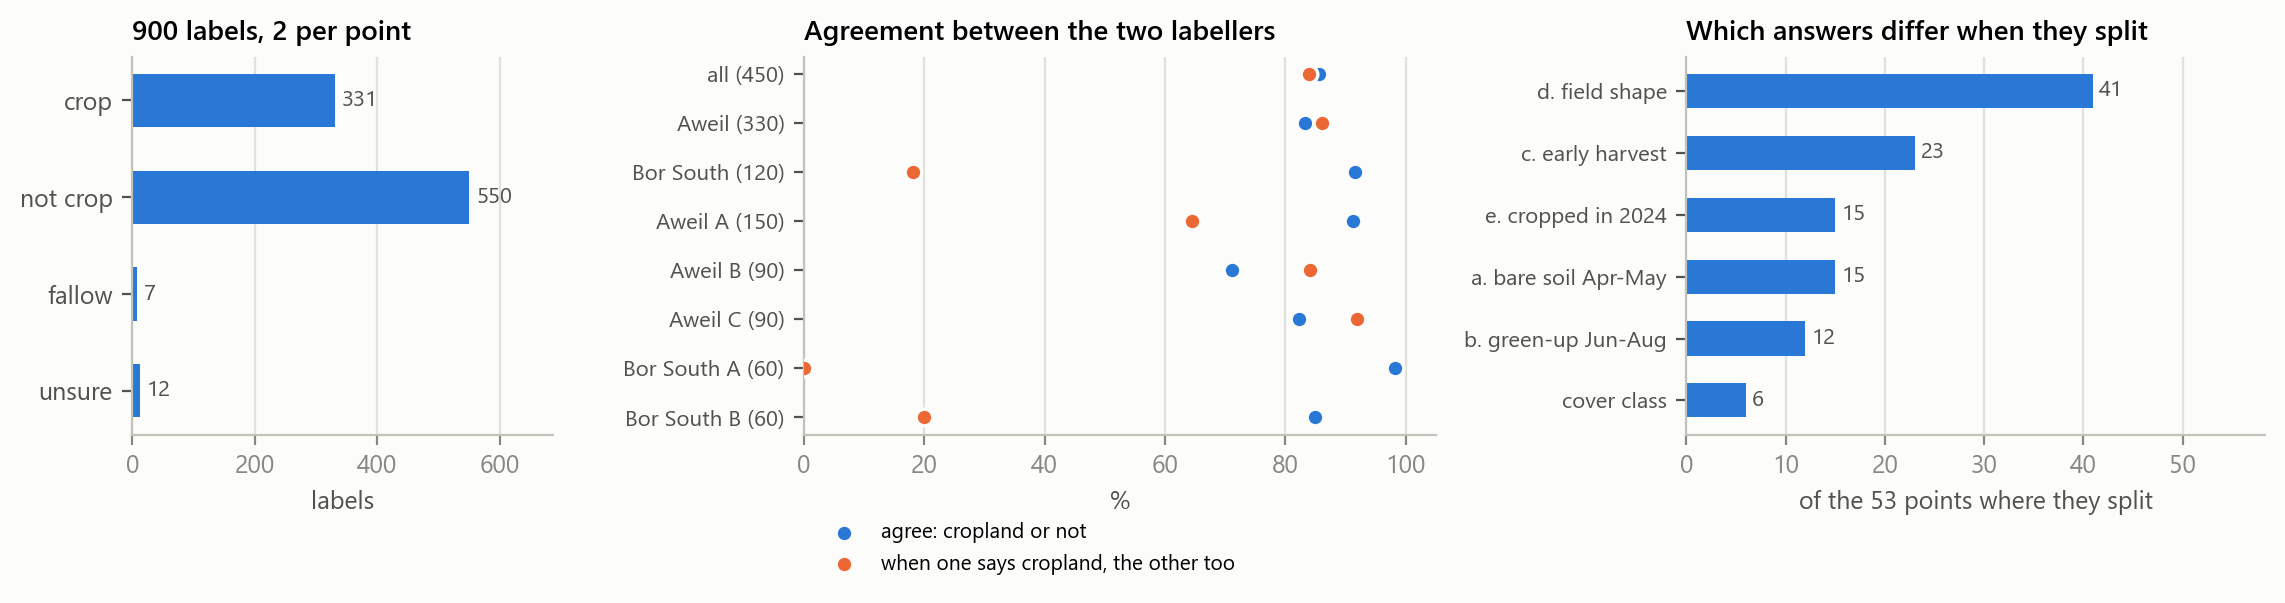

In [15]:
d = L.pairs()
d["pair"] = d.labeller_1 + " & " + d.labeller_2
lab = pd.concat([L.summary(d).assign(by="all"),
                 L.summary(d, by="area").assign(by="area"),
                 L.summary(d, by=["area", "stratum"]).assign(by="area x stratum"),
                 L.summary(d, by="split").assign(by="split"),
                 L.summary(d, by="pair").assign(by="pair")], ignore_index=True)
lab["group"] = lab.group.astype(str)
lab.to_csv(D.TABLES / "label_agreement.csv", index=False)
L.confusion(d).to_csv(D.TABLES / "label_confusion.csv")
split_points, causes = L.disagreement_causes(d)
split_points.to_csv(D.TABLES / "label_disagreement_causes_per_point.csv", index=False)
causes.to_csv(D.TABLES / "label_disagreement_causes.csv")
eff = L.effort()
eff.to_csv(D.TABLES / "label_effort.csv")
print(f"{len(d)} of 450 points labelled twice")
display(lab[["by", "group", "points", "cropland_agree", "cropland_kappa", "cropland_pos_agree", "cropland_neg_agree", "cropland_either_says"]].round(3))
display(L.confusion(d))
display(eff.round(2))
display(causes)
all_labels = pd.concat([pd.read_csv(f) for f in sorted((L.C.HERE / "labels").glob("sample_labels_*.csv"))]).label.value_counts()
groups = lab[lab.by.isin(["all", "area", "area x stratum"])].copy()
groups["group"] = groups.group.str.replace(r"[()',]", "", regex=True).str.replace("aweil", "Aweil").str.replace("bor_south", "Bor South")
display(Image(F.annotation_summary(all_labels, groups, causes)))

## 9. Methodology: how many points does a check need?

Neyman-optimal sample size for a target coefficient of variation (Olofsson et al. 2014; Skakun 2025; Adebayo et al. 2026, Eq. 5), with our Aweil strata weights and a range of crop shares per stratum (the real ones come from the labels). The first line checks the code against Adebayo et al. (Table 4, Kenya, GLAD: 616 points). The last column shows where the uncertainty comes from: the stratum where no map sees crop.

In [16]:
W, p = E.one_map_strata(0.09, 0.575, 0.630)
print(f"check, Kenya / GLAD: {E.n_opt(W, p, 0.10):.0f} points (paper 616)")
strata = pd.read_csv("strata_areas.csv")
Wa = strata[strata.area == "aweil"].share.to_numpy()
n_now = np.array([150, 90, 90])
grid = []
for pA in (0.01, 0.02, 0.03, 0.05):
    for pB in (0.2, 0.4):
        p = np.array([pA, pB, 0.6])
        se = E.se_share(Wa, p, n_now)
        f = (Wa * p).sum()
        grid.append({"p_A (0 maps)": pA, "p_B (1-2)": pB, "p_C (3+)": 0.6, "crop_pct": 100 * f,
                     "ci95_pp_with_150_90_90": 196 * se, "cv_pct": 100 * se / f,
                     "n_for_cv_20pct": E.n_opt(Wa, p, 0.20), "n_for_cv_10pct": E.n_opt(Wa, p, 0.10),
                     "share_of_variance_from_A": Wa[0] ** 2 * p[0] * (1 - p[0]) / (n_now[0] - 1) / se ** 2})
grid = pd.DataFrame(grid)
grid.to_csv(D.TABLES / "sample_size_planning_aweil.csv", index=False)
grid.round(2)

check, Kenya / GLAD: 591 points (paper 616)


,p_A (0 maps),p_B (1-2),p_C (3+),crop_pct,ci95_pp_with_150_90_90,cv_pct,n_for_cv_20pct,n_for_cv_10pct,share_of_variance_from_A
0,0.01,0.2,0.6,2.08,1.57,38.35,759.39,3037.56,0.94
1,0.01,0.4,0.6,3.03,1.59,26.82,387.30,1549.22,0.91
2,0.02,0.2,0.6,3.03,2.17,36.50,638.60,2554.40,0.97
3,0.02,0.4,0.6,3.98,2.19,28.07,392.69,1570.74,0.95
4,0.03,0.2,0.6,3.98,2.63,33.69,524.07,2096.27,0.98
5,0.03,0.4,0.6,4.93,2.65,27.40,358.89,1435.57,0.97
6,0.05,0.2,0.6,5.88,3.35,29.02,373.43,1493.73,0.99
7,0.05,0.4,0.6,6.83,3.36,25.10,287.89,1151.57,0.98


## 9b. Methodology: does the 95% interval hold? (simulation)

Before any result exists we check the area interval on made-up data with our exact design: Aweil and Bor South strata weights and points, a range of crop rates per stratum, and for the main measure (share of box) the share of each cropland box drawn from the five labelling classes, with smaller fields where no map sees crop. 20,000 samples per case (`evaluation.simulate_interval_coverage`).

The estimator is unbiased, but the usual ±1.96 SE interval holds the truth far less than 95% of the time, and every miss lies below the truth: when no cropland box falls in stratum A, that stratum adds nothing to the estimate or its error. The adjusted interval (`evaluation.area_interval`) keeps the estimate and the lower bound and takes the upper bound from a cautious variance (one more cropland and one more empty box per stratum, with the cropland shares of the whole area). Proposed as an addition to METHODOLOGY.md (report notes, file 06, section 6.7).

In [17]:
mix = {"A": [0.5, 0.3, 0.15, 0.05], "B": [0.25, 0.35, 0.25, 0.15], "C": [0.15, 0.3, 0.3, 0.25]}
Wb = strata[strata.area == "bor_south"].share.to_numpy()
cov = []
for measure in ("box holds cropland", "share of box"):
    for pA in (0.005, 0.01, 0.02, 0.05, 0.10):
        for pB in (0.2, 0.4):
            sm = None if measure == "box holds cropland" else [mix["A"], mix["B"], mix["C"]]
            cov.append({"area": "Aweil (150/90/90)", "measure": measure, "p_A": pA, "p_B": pB, "p_C": 0.6,
                        **V.simulate_interval_coverage(Wa, [150, 90, 90], [pA, pB, 0.6], sm)})
    for pA in (0.005, 0.01, 0.02, 0.05):
        for pB in (0.02, 0.10):
            sm = None if measure == "box holds cropland" else [mix["A"], mix["B"]]
            cov.append({"area": "Bor South (60/60)", "measure": measure, "p_A": pA, "p_B": pB, "p_C": None,
                        **V.simulate_interval_coverage(Wb, [60, 60], [pA, pB], sm)})
cov = pd.DataFrame(cov)
cov.to_csv(D.TABLES / "interval_coverage_simulation.csv", index=False)
cov.groupby(["area", "measure"])[["coverage_usual", "below_truth_usual", "coverage_adjusted", "upper_extra_pp"]].agg(["min", "max"]).round(3)

coverage_usual        below_truth_usual        coverage_adjusted      upper_extra_pp       
                                                min    max               min    max               min  max            min    max
area              measure                                                                                                       
Aweil (150/90/90) box holds cropland          0.689  0.937             0.051  0.310             0.939  1.0          0.093  0.653
                  share of box                0.785  0.893             0.103  0.214             0.994  1.0          0.408  0.773
Bor South (60/60) box holds cropland          0.467  0.885             0.112  0.533             0.949  1.0          0.718  2.229
                  share of box                0.571  0.811             0.188  0.429             0.876  1.0          0.421  1.156

## 10. Key numbers for the report

One table of the numbers the text quotes, so the report and poster read them from one place.

In [18]:
def pct(a, m):
    return panels[AREA_NAME[a]][m]

s7 = [m for m in D.MAPS] + ["asap_v04"]
aw22 = show[(show.unit == "Aweil counties") & (show.year == 2022)].set_index("map").flooded_crop_ha
na22 = show[(show.unit == "South Sudan (south of 10 N)") & (show.year == 2022)].set_index("map").flooded_crop_ha
bs25 = show[(show.unit == "Bor South") & (show.year == 2025)].set_index("map").flooded_crop_ha
iou_off = iou_aweil.values[~np.eye(len(iou_aweil), dtype=bool)]
key = {
    "Aweil crop share, lowest map (%)": min(pct("aweil", m) for m in s7),
    "Aweil crop share, highest map (%)": max(pct("aweil", m) for m in s7),
    "Aweil CFSAM 2025 cereal area (% of land)": 100 * cfsam[("aweil", 2025)] / land_area["aweil"],
    "Aweil CFSAM 2022 cereal area (% of land)": 100 * cfsam[("aweil", 2022)] / land_area["aweil"],
    "Bor South crop share, Dynamic World 2025 (%)": pct("bor_south", "dynamicworld_2025"),
    "Bor South crop share, highest other map (%)": max(pct("bor_south", m) for m in s7 if m != "dynamicworld_2025"),
    "Aweil land no map calls crop (%)": agree_tab.loc["all counties", "0 maps"],
    "Aweil land all 7 maps call crop (%)": agree_tab.loc["all counties", "7 maps"],
    "Aweil land >= 4 maps call crop (%)": agree_tab.loc["all counties", ["4 maps", "5 maps", "6 maps", "7 maps"]].sum(),
    "Aweil pairwise IoU, best pair": np.nanmax(iou_off),
    "Aweil pairwise IoU, median pair": np.nanmedian(iou_off),
    "National crop, lowest map (Mha)": national.loc[s7, "crop_Mha"].min(),
    "National crop, highest map (Mha)": national.loc[s7, "crop_Mha"].max(),
    "National CFSAM 2025 cereal area (Mha)": refn[("CFSAM", 2025, "cereal harvested area")] / 1e6,
    "National FAOSTAT arable land (Mha)": refn[("FAOSTAT", 2022, "arable land")] / 1e6,
    "Aweil 2022 flooded cropland, lowest map (ha)": aw22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].min(),
    "Aweil 2022 flooded cropland, highest map (ha)": aw22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].max(),
    "National 2022 flooded cropland, lowest map (ha)": na22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].min(),
    "National 2022 flooded cropland, highest map (ha)": na22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].max(),
    "National 2022 flooded cropland, ASAP (ha)": na22["asap_v04"],
    "CFSAM 2022 cultivated land damaged by floods (ha)": 130000,
    "Bor South 2025 flooded cropland, Dynamic World (ha)": bs25["dynamicworld_2025"],
    "Bor South 2025 flooded cropland, all other maps (ha, max)": bs25[[m for m in s7 if m != "dynamicworld_2025"]].max(),
    "Labelled twice so far (points)": len(d),
    "Labeller splits on cropland (points)": causes["split points"],
    "Exact label agreement (%)": 100 * lab.loc[lab.by == "all", "label_agree"].iloc[0],
    "Exact label agreement (points)": round(lab.loc[lab.by == "all", "label_agree"].iloc[0] * len(d)),
    "Labels given (judgements)": int(all_labels.sum()),
    "Splits where field shape answers differ (points)": causes["cue differs: d. field shape"],
    "Labellers agree cropland vs not, Aweil (%)": 100 * lab.loc[(lab.by == "area") & (lab.group == "aweil"), "cropland_agree"].iloc[0],
    "Cohen's kappa cropland vs not, Aweil": lab.loc[(lab.by == "area") & (lab.group == "aweil"), "cropland_kappa"].iloc[0],
    "Cohen's kappa cropland vs not, Bor South": lab.loc[(lab.by == "area") & (lab.group == "bor_south"), "cropland_kappa"].iloc[0],
    "Labellers agree cropland vs not (%)": 100 * lab.loc[lab.by == "all", "cropland_agree"].iloc[0],
    "Cohen's kappa cropland vs not": lab.loc[lab.by == "all", "cropland_kappa"].iloc[0],
    "Esri F1 in Mali, Kerner et al. 2024": pub.loc["esri_2025", "kerner_f1_mali"],
    "Esri accuracy in Mali, Kerner et al. 2024": pub.loc["esri_2025", "kerner_accuracy_mali"],
    "Rank corr. published recall (Kerner) vs Aweil crop share": rho.loc["Aweil counties", "Kerner recall (7 maps)"],
    "Rank corr. published recall (Kerner) vs Bor South crop share": rho.loc["Bor South", "Kerner recall (7 maps)"],
    "Aweil land (ha)": land_area["aweil"],
    "Bor South land (ha)": land_area["bor_south"],
    "Aweil land all 7 maps call crop (ha)": agree_tab.loc["all counties", "7 maps"] / 100 * land_area["aweil"],
    "Usual interval coverage, lowest (%)": 100 * cov.coverage_usual.min(),
    "Usual interval coverage, highest (%)": 100 * cov.coverage_usual.max(),
    "Adjusted interval coverage, lowest (%)": 100 * cov.coverage_adjusted.min(),
    "Adjusted interval coverage, lowest in Aweil (%)": 100 * cov[cov.area.str.startswith("Aweil")].coverage_adjusted.min(),
}
key = pd.Series(key, name="value")
key.to_csv(D.TABLES / "key_numbers.csv")
key.round(3)

Aweil crop share, lowest map (%)                                      0.216
Aweil crop share, highest map (%)                                     1.919
Aweil CFSAM 2025 cereal area (% of land)                              3.615
Aweil CFSAM 2022 cereal area (% of land)                              5.408
Bor South crop share, Dynamic World 2025 (%)                          8.990
Bor South crop share, highest other map (%)                           0.249
Aweil land no map calls crop (%)                                     94.966
Aweil land all 7 maps call crop (%)                                   0.000
Aweil land >= 4 maps call crop (%)                                    0.065
Aweil pairwise IoU, best pair                                         0.161
Aweil pairwise IoU, median pair                                       0.042
National crop, lowest map (Mha)                                       0.223
National crop, highest map (Mha)                                      1.797
National CFS